# REFIT washing-machine NILM: Seq2Point, Seq2Seq

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from pathlib import Path
import re, sys, shutil, subprocess, urllib.request, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import random
from datetime import datetime
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import warnings
warnings.filterwarnings('ignore')

In [3]:
AUTO_DOWNLOAD=True
MODEL_HOUSES=[1,2,3]
START_DATE='2014-06-01'
END_DATE='2014-11-01'
WINDOW=61
ACTIVE_W=20.0
TRAIN_FRACTION=.70
VAL_FRACTION=.15
MAX_TRAIN_WINDOWS_PER_HOME=120_000
EPOCHS=30
BATCH_SIZE=256
SEED=42

EXCLUDE_ISSUE_WINDOWS=True
LEARNING_RATE=0.0005

ACTIVE_SAMPLE_WEIGHT=1.0
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
# DATA_DIR = Path("/content/drive/MyDrive/refit/refit_data")
# OUTPUT_DIR = Path("/content/drive/MyDrive/refit/model_results")

DATA_DIR = Path("../data/cleaned")
OUTPUT_DIR = Path("../artifacts/model_results")
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

In [5]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f'Extracted CSV folder not found: {DATA_DIR}.'
    )
CSV_FILES = sorted(p for p in DATA_DIR.rglob('*') if p.is_file() and p.suffix.lower() == '.csv')
print(f'Found {len(CSV_FILES)} CSV file(s) under {DATA_DIR}')
print('Sample names:', [str(p.relative_to(DATA_DIR)) for p in CSV_FILES[:5]])


COLS = ['Time', 'Unix', 'Aggregate'] + [f'Appliance{i}' for i in range(1, 10)] + ['Issues']


Found 20 CSV file(s) under /content/drive/MyDrive/refit/refit_data
Sample names: ['CLEAN_House1.csv', 'CLEAN_House10.csv', 'CLEAN_House11.csv', 'CLEAN_House12.csv', 'CLEAN_House13.csv']


In [6]:
def read_selected_chunks(path, channels, include_issues=True, chunksize=250_000):
    chosen = ['Time', 'Aggregate'] + [f'Appliance{i}' for i in channels]
    if include_issues:
        chosen += ['Issues']
    for chunk in pd.read_csv(
        path, header=None, names=(COLS if include_issues else COLS[:-1]),
        usecols=chosen, chunksize=chunksize, low_memory=False,
        skipinitialspace=True, on_bad_lines='warn'
    ):
        # Some CSVs have a header row. Such rows parse to NaT and are discarded.
        chunk['Time'] = pd.to_datetime(chunk['Time'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
        chunk = chunk.dropna(subset=['Time'])
        for name in chosen[1:]:
            chunk[name] = pd.to_numeric(chunk[name], errors='coerce')
        yield chunk

In [7]:
HOUSES=[1,2,3,4,5,6,7,8,9,10,11,13,15,16,17,18,19,20,21]
WASHER_CHANNELS={1:[5],2:[2],3:[6],4:[4,5],5:[3],6:[2],7:[5],8:[4],9:[3],
                 10:[5],11:[3],13:[3],15:[3],16:[5],17:[4],18:[5],19:[2],20:[4],21:[3]}

In [8]:
def get_clean_file(house):
    pattern = re.compile(r'(?i)house[_\s-]?' + str(house) + r'(?!\d)')
    matches = [p for p in CSV_FILES if pattern.search(p.stem)]
    preferred = [p for p in matches if 'clean' in p.name.lower() or
                 any('clean' in part.lower() for part in p.parts[-3:-1])]
    if preferred:
        matches = preferred
    if not matches:
        raise FileNotFoundError(
            f'No cleaned CSV found for House {house} below {DATA_DIR}. '
        )
    if len(matches) > 1:
        raise RuntimeError(
            f'Found multiple possible cleaned files for House {house}: {matches}. '
        )
    return matches[0]

missing = []
check_rows = []
for h in HOUSES:
    if h not in WASHER_CHANNELS:
        raise ValueError(f'House {h} has no configured washing-machine channel.')
    try:
        f = get_clean_file(h)
        check_rows.append({'house': h, 'washer_channels': WASHER_CHANNELS[h],
                           'clean_csv': str(f.relative_to(DATA_DIR))})
    except FileNotFoundError as exc:
        missing.append(str(exc))
if missing:
    raise FileNotFoundError('Some selected households are missing:\n' + '\n'.join(missing))
display(pd.DataFrame(check_rows))
print(f'\nVerified: all {len(HOUSES)} selected homes have cleaned REFIT CSV files. Ready for analysis.')

,house,washer_channels,clean_csv
0,1,[5],CLEAN_House1.csv
1,2,[2],CLEAN_House2.csv
2,3,[6],CLEAN_House3.csv
3,4,"[4, 5]",CLEAN_House4.csv
4,5,[3],CLEAN_House5.csv
5,6,[2],CLEAN_House6.csv
6,7,[5],CLEAN_House7.csv
7,8,[4],CLEAN_House8.csv
8,9,[3],CLEAN_House9.csv
9,10,[5],CLEAN_House10.csv



Verified: all 19 selected homes have cleaned REFIT CSV files. Ready for analysis.


In [9]:
def load_clean_minutes(house, start=None, end=None):
    """Stream cleaned CSV; return observed per-minute mean watts without zero-filling outages."""
    chan = WASHER_CHANNELS[house]
    path = get_clean_file(house)
    pieces = []; first = None; last = None; parsed = 0
    for c in read_selected_chunks(path, chan, include_issues=True):
        if start is not None:
            c = c[c.Time >= pd.Timestamp(start)]
        if end is not None:
            c = c[c.Time < pd.Timestamp(end)]
        if c.empty:
            continue
        parsed += len(c)
        first = c.Time.min() if first is None else min(first, c.Time.min())
        last = c.Time.max() if last is None else max(last, c.Time.max())
        c['Aggregate'] = c['Aggregate'].where(c['Aggregate'].between(0, 25000))
        wm_cols = [f'Appliance{i}' for i in chan]
        for k in wm_cols:
            c[k] = c[k].where(c[k].between(0, 4000))
        # For House 4 both channels must be present to claim a total washing-machine reading.
        c['wm'] = c[wm_cols].sum(axis=1, min_count=len(chan))
        c['issues'] = c['Issues'].fillna(0).gt(0).astype(int)
        c['minute'] = c.Time.dt.floor('min')
        b = c.groupby('minute', sort=True).agg(
            agg_sum=('Aggregate','sum'), agg_n=('Aggregate','count'),
            wm_sum=('wm','sum'), wm_n=('wm','count'),
            issue_n=('issues','sum'), rows=('wm','size')
        )
        pieces.append(b)
    if not pieces:
        raise ValueError(f'No cleaned data for House {house} in the requested date range.')
    # Recombine sums and counts across chunk boundaries for correct 1-minute means.
    agg = pd.concat(pieces).groupby(level=0).sum().sort_index()
    minute = pd.DataFrame(index=agg.index)
    minute['aggregate_w'] = (agg.agg_sum / agg.agg_n.replace(0, np.nan)).astype('float32')
    minute['washer_w'] = (agg.wm_sum / agg.wm_n.replace(0, np.nan)).astype('float32')
    minute['issues_flag'] = agg.issue_n.gt(0)
    minute['observed_rows'] = agg.rows.astype('int32')
    minute = minute.asfreq('1min')
    minute['issues_flag'] = minute['issues_flag'].astype('boolean').fillna(False).astype(bool)
    minute['observed_rows'] = minute['observed_rows'].fillna(0).astype('int32')
    print(f'House {house}: {parsed:,} readings | {len(minute):,} minute slots | '
          f'{first} to {last} | {len(chan)} washer channel(s)')
    return minute

## 1. Load aligned 1-minute aggregate and labels; audit coverage and flags

In [10]:

assert WINDOW%2==1 and WINDOW>=3
assert all(len(WASHER_CHANNELS[h])==1 for h in MODEL_HOUSES), 'Use unambiguous single-meter homes in this implementation.'
data_by_house={}; audit=[]
for h in MODEL_HOUSES:
    try: minute=load_clean_minutes(h,START_DATE,END_DATE)
    except ValueError as err:
        print('Skipping:',err); continue
    good=minute.aggregate_w.notna() & minute.washer_w.notna()
    if EXCLUDE_ISSUE_WINDOWS: good &= ~minute.issues_flag
    audit.append({'house':h,'first':str(minute.index.min()),'last':str(minute.index.max()),
         'minutes':len(minute),'paired_valid_minutes':int(good.sum()),
         'missing_or_excluded_pct':float(100*(~good).mean()),
         'issues_flagged_minutes':int(minute.issues_flag.sum())})
    data_by_house[h]=minute.assign(usable=good)
if not data_by_house:
  raise RuntimeError('No model homes loaded. Check START_DATE/END_DATE and data files.')
audit_df=pd.DataFrame(audit)
display(audit_df)
audit_df.to_csv(OUTPUT_DIR/'03_data_coverage.csv',index=False)

House 1: 1,693,820 readings | 220,320 minute slots | 2014-06-01 00:00:06 to 2014-10-31 23:59:58 | 1 washer channel(s)
House 2: 1,709,841 readings | 220,320 minute slots | 2014-06-01 00:00:05 to 2014-10-31 23:59:57 | 1 washer channel(s)
House 3: 1,895,861 readings | 220,320 minute slots | 2014-06-01 00:00:05 to 2014-10-31 23:59:55 | 1 washer channel(s)


,house,first,last,minutes,paired_valid_minutes,missing_or_excluded_pct,issues_flagged_minutes
0,1,2014-06-01 00:00:00,2014-10-31 23:59:00,220320,209641,4.847041,3122
1,2,2014-06-01 00:00:00,2014-10-31 23:59:00,220320,213728,2.992012,4438
2,3,2014-06-01 00:00:00,2014-10-31 23:59:00,220320,206464,6.289034,7176


In [11]:
data_by_house

{1:                      aggregate_w  washer_w  issues_flag  observed_rows  usable
 minute                                                                        
 2014-06-01 00:00:00   469.111115       0.0        False              9    True
 2014-06-01 00:01:00   467.799988       0.0        False             10    True
 2014-06-01 00:02:00   471.500000       0.0        False             10    True
 2014-06-01 00:03:00   468.500000       0.0        False             10    True
 2014-06-01 00:04:00   469.777771       0.0        False              9    True
 ...                          ...       ...          ...            ...     ...
 2014-10-31 23:55:00   173.000000       0.0        False              9    True
 2014-10-31 23:56:00   173.000000       0.0        False              9    True
 2014-10-31 23:57:00   173.111115       0.0        False              9    True
 2014-10-31 23:58:00   172.666672       0.0        False              9    True
 2014-10-31 23:59:00   173.000000    

## 2. Chronological partitioning and safe window extraction

In [12]:
from numpy.lib.stride_tricks import sliding_window_view

def split_timewise(df):
    n=len(df); i=int(n*TRAIN_FRACTION); j=int(n*(TRAIN_FRACTION+VAL_FRACTION))
    if i < WINDOW or (j-i) < WINDOW or (n-j) < WINDOW:
        raise ValueError('Insufficient observations for the chosen split/window.')
    return {'train':df.iloc[:i], 'val':df.iloc[i:j], 'test':df.iloc[j:]}

def select_windows(frame,window=WINDOW):
    """Seq2Point: every aggregate input valid; only midpoint washer label required."""
    empty=(np.empty((0,window),dtype=np.float32),
           np.empty(0,dtype=np.float32),pd.DatetimeIndex([]))
    if len(frame)<window:
        return empty
    a=frame.aggregate_w.to_numpy(dtype=np.float32)
    y=frame.washer_w.to_numpy(dtype=np.float32)
    input_ok=np.isfinite(a)
    if EXCLUDE_ISSUE_WINDOWS:
        input_ok &= ~frame.issues_flag.to_numpy(dtype=bool)
    nwin=len(frame)-window+1
    mid=window//2
    midpoint_ok=np.isfinite(y[mid:mid+nwin])
    if EXCLUDE_ISSUE_WINDOWS:
        midpoint_ok &= ~frame.issues_flag.to_numpy(dtype=bool)[mid:mid+nwin]
    eligible=sliding_window_view(input_ok,window).all(axis=1) & midpoint_ok
    positions=np.flatnonzero(eligible)
    X=sliding_window_view(a,window)[positions].copy()
    targets=y[positions+mid].copy()
    times=frame.index[positions+mid]
    return X,targets,times

splits={h:split_timewise(df) for h,df in data_by_house.items()}
for h,parts in splits.items():
    print(f'House {h}:',', '.join(f'{s} {len(v):,} minutes ({v.index[0]} → {v.index[-1]})' for s,v in parts.items() if len(v)))
    assert parts['train'].index.max()<parts['val'].index.min()<parts['test'].index.min()


House 1: train 154,224 minutes (2014-06-01 00:00:00 → 2014-09-16 02:23:00), val 33,048 minutes (2014-09-16 02:24:00 → 2014-10-09 01:11:00), test 33,048 minutes (2014-10-09 01:12:00 → 2014-10-31 23:59:00)
House 2: train 154,224 minutes (2014-06-01 00:00:00 → 2014-09-16 02:23:00), val 33,048 minutes (2014-09-16 02:24:00 → 2014-10-09 01:11:00), test 33,048 minutes (2014-10-09 01:12:00 → 2014-10-31 23:59:00)
House 3: train 154,224 minutes (2014-06-01 00:00:00 → 2014-09-16 02:23:00), val 33,048 minutes (2014-09-16 02:24:00 → 2014-10-09 01:11:00), test 33,048 minutes (2014-10-09 01:12:00 → 2014-10-31 23:59:00)


## 3. Training-only normalization and reproducible sample selection

In [13]:
train_mains=np.concatenate([p['train'].loc[p['train'].usable,'aggregate_w'].to_numpy() for p in splits.values()])
mu=float(train_mains.mean()); sigma=max(float(train_mains.std()),1.0)
print(f'Aggregate normalization (training only): mean={mu:.2f} W, std={sigma:.2f} W')
rng=np.random.default_rng(SEED)

def training_subset(X,y,limit):
    """Sample with at most 50% active points; cap runtime without discarding all off windows."""
    if len(y)<=limit: return X,y
    on=np.flatnonzero(y>=ACTIVE_W); off=np.flatnonzero(y<ACTIVE_W)
    n_on=min(len(on),limit//2); n_off=min(len(off),limit-n_on)

    remaining=limit-n_on-n_off
    if remaining: n_on+=min(remaining,len(on)-n_on)
    indices=np.sort(np.r_[rng.choice(on,n_on,replace=False),rng.choice(off,n_off,replace=False)])
    return X[indices],y[indices]

X_train_parts=[]; y_train_parts=[]; X_val_parts=[]; y_val_parts=[]
for h,part in splits.items():
    X,y,_=select_windows(part['train'])
    X,y=training_subset(X,y,MAX_TRAIN_WINDOWS_PER_HOME)
    Xv,yv,_=select_windows(part['val'])
    print(f'House {h}: train windows {len(y):,} (active {(y>=ACTIVE_W).sum():,}), val windows {len(yv):,}')
    if len(y): X_train_parts.append(X); y_train_parts.append(y)
    if len(yv): X_val_parts.append(Xv); y_val_parts.append(yv)
if not X_train_parts or not X_val_parts: raise RuntimeError('Insufficient contiguous valid training/validation windows; widen date range or inspect missing coverage.')
X_train=np.concatenate(X_train_parts); y_train=np.concatenate(y_train_parts)
X_val=np.concatenate(X_val_parts); y_val=np.concatenate(y_val_parts)
X_train=((X_train-mu)/sigma)[...,None].astype('float32')
X_val=((X_val-mu)/sigma)[...,None].astype('float32')

y_train_scaled=(y_train/1000).astype('float32');y_val_scaled=(y_val/1000).astype('float32')

weights=np.where(y_train>=ACTIVE_W,ACTIVE_SAMPLE_WEIGHT,1.0).astype('float32')
print(f'Train ON percentage: {100*np.mean(y_train>=ACTIVE_W):.2f}%; val ON percentage: {100*np.mean(y_val>=ACTIVE_W):.2f}%')
print('Training input shape:',X_train.shape,'Validation input shape:',X_val.shape)

Aggregate normalization (training only): mean=408.94 W, std=789.31 W
House 1: train windows 99,497 (active 22), val windows 21,619
House 2: train windows 89,416 (active 64), val windows 17,292
House 3: train windows 71,683 (active 148), val windows 17,042
Train ON percentage: 0.09%; val ON percentage: 0.33%
Training input shape: (260596, 61, 1) Validation input shape: (55953, 61, 1)


## 4. Seq2Point

### 4.1 Seq2Point CNN and validation-only early stopping

In [14]:
def make_seq2point(window_length):
    inp = keras.Input(shape=(window_length,1), name='aggregate_window_1min')
    x = layers.Conv1D(30, 10, strides=1, padding='valid', activation='relu', name='conv_1')(inp)
    x = layers.Conv1D(30,  8, strides=1, padding='valid', activation='relu', name='conv_2')(x)
    x = layers.Conv1D(40,  6, strides=1, padding='valid', activation='relu', name='conv_3')(x)
    x = layers.Conv1D(50,  5, strides=1, padding='valid', activation='relu', name='conv_4')(x)
    x = layers.Conv1D(50,  5, strides=1, padding='valid', activation='relu', name='conv_5')(x)
    x = layers.Flatten(name='flatten')(x)
    x = layers.Dense(1024, activation='relu', name='dense_1024')(x)
    out = layers.Dense(1, activation='linear', name='washer_midpoint')(x)
    return keras.Model(inputs=inp, outputs=out, name='Seq2PointModel')

model = make_seq2point(WINDOW)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
              loss='mse', metrics=[keras.metrics.MeanAbsoluteError(name='scaled_mae')])
model.summary()
print('Expected conv filters:', [layer.filters for layer in model.layers if isinstance(layer,layers.Conv1D)])
assert [l.filters for l in model.layers if isinstance(l,layers.Conv1D)] == [30,30,40,50,50]
assert [l.kernel_size[0] for l in model.layers if isinstance(l,layers.Conv1D)] == [10,8,6,5,5]
assert model.output_shape == (None,1)

Model: "Seq2PointModel"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aggregate_window_1min           │ (None, 61, 1)          │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv1D)                 │ (None, 52, 30)         │           330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv1D)                 │ (None, 45, 30)         │         7,230 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv1D)                 │ (None, 40, 40)         │         7,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv1D)                 │ (None, 36, 50)         │        10,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_5 (Conv1D)                 │ (None, 32, 50)         │        12,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1024 (Dense)              │ (None, 1024)           │     1,639,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ washer_midpoint (Dense)         │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,677,849 (6.40 MB)

 Trainable params: 1,677,849 (6.40 MB)

 Non-trainable params: 0 (0.00 B)

Expected conv filters: [30, 30, 40, 50, 50]


Epoch 1/30
1018/1018 - 20s - 19ms/step - loss: 2.1374e-04 - scaled_mae: 0.0011 - val_loss: 8.1076e-04 - val_scaled_mae: 0.0013
Epoch 2/30
1018/1018 - 6s - 6ms/step - loss: 1.5778e-04 - scaled_mae: 7.0960e-04 - val_loss: 8.0764e-04 - val_scaled_mae: 0.0014
Epoch 3/30
1018/1018 - 7s - 7ms/step - loss: 1.5776e-04 - scaled_mae: 7.4541e-04 - val_loss: 8.0688e-04 - val_scaled_mae: 0.0014
Epoch 4/30
1018/1018 - 10s - 9ms/step - loss: 1.5755e-04 - scaled_mae: 7.5789e-04 - val_loss: 8.0618e-04 - val_scaled_mae: 0.0017
Epoch 5/30
1018/1018 - 7s - 7ms/step - loss: 1.5776e-04 - scaled_mae: 7.8847e-04 - val_loss: 8.0914e-04 - val_scaled_mae: 0.0014
Epoch 6/30
1018/1018 - 9s - 9ms/step - loss: 1.5784e-04 - scaled_mae: 7.7407e-04 - val_loss: 8.0808e-04 - val_scaled_mae: 0.0013
Epoch 7/30
1018/1018 - 7s - 6ms/step - loss: 1.5776e-04 - scaled_mae: 7.8036e-04 - val_loss: 8.0095e-04 - val_scaled_mae: 9.4540e-04
Epoch 8/30
1018/1018 - 7s - 7ms/step - loss: 1.5506e-04 - scaled_mae: 8.1249e-04 - val_loss: 8

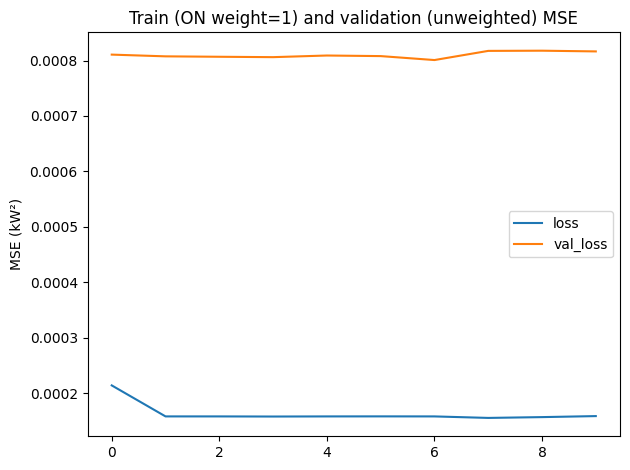

In [15]:
history=model.fit(X_train,y_train_scaled,sample_weight=weights,
    validation_data=(X_val,y_val_scaled),epochs=EPOCHS,batch_size=BATCH_SIZE,verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)])
pd.DataFrame(history.history)[['loss','val_loss']].plot(title=f'Train (ON weight={ACTIVE_SAMPLE_WEIGHT:g}) and validation (unweighted) MSE')
plt.ylabel('MSE (kW²)');plt.tight_layout();plt.savefig(OUTPUT_DIR/'03_learning_curve.png',dpi=150);plt.show()

### 4.2 Held-out test predictions; fair zero baseline; per-home and pooled metrics

In [16]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,precision_recall_fscore_support

def score(y_true,y_pred):
    y_true=np.asarray(y_true); y_pred=np.asarray(y_pred)
    mae=float(mean_absolute_error(y_true,y_pred))
    rmse=float(np.sqrt(mean_squared_error(y_true,y_pred)))
    truth=y_true>=ACTIVE_W; guess=y_pred>=ACTIVE_W
    prec,rec,f1,_=precision_recall_fscore_support(truth,guess,average='binary',zero_division=0)
    true_kwh=float(y_true.sum()/60000);pred_kwh=float(y_pred.sum()/60000)
    sae=float(abs(true_kwh-pred_kwh)/true_kwh) if true_kwh>0 else np.nan
    return {'MAE_W':mae,'RMSE_W':rmse,'precision_on':float(prec),'recall_on':float(rec),
            'F1_on':float(f1),'true_kWh':true_kwh,'pred_kWh':pred_kwh,'SAE':sae}

predictions=[]; scores=[]
for h,part in splits.items():
    Xt,yt,times=select_windows(part['test'])
    if len(yt)==0:
        print('Skipping House',h,'— not enough valid test windows.');continue
    Xn=((Xt-mu)/sigma)[...,None].astype('float32')
    p=np.maximum(0,model.predict(Xn,batch_size=2048,verbose=0).ravel()*1000)

    p=np.minimum(p,np.maximum(0,Xt[:,WINDOW//2]))
    pred=pd.DataFrame({'house':h,'actual_w':yt,'predicted_w':p,'aggregate_w':Xt[:,WINDOW//2]},index=times)
    pred.index.name='Time'; predictions.append(pred)
    for method,estimate in [('CNN',p),('Always off',np.zeros_like(p))]:
        scores.append({'house':h,'method':method,'n_test_minutes':len(yt),**score(yt,estimate)})
if not predictions: raise RuntimeError('No evaluable test windows.')
pred_df=pd.concat(predictions).sort_index(kind='stable')
metrics_df=pd.DataFrame(scores)
display(metrics_df.round(3))
pred_df.to_csv(OUTPUT_DIR/'03_test_predictions.csv')
metrics_df.to_csv(OUTPUT_DIR/'03_test_metrics.csv',index=False)
for method in ['CNN','Always off']:
    dd=pred_df
    print(method,':',score(dd.actual_w,dd.predicted_w if method=='CNN' else np.zeros(len(dd))))

,house,method,n_test_minutes,MAE_W,RMSE_W,precision_on,recall_on,F1_on,true_kWh,pred_kWh,SAE
0,1,CNN,19977,0.362,5.766,0.000,0.000,0.000,0.036,0.086,1.373
1,1,Always off,19977,0.109,5.666,0.000,0.000,0.000,0.036,0.000,1.000
2,2,CNN,19006,3.149,74.923,0.000,0.000,0.000,0.950,0.052,0.946
3,2,Always off,19006,2.998,75.002,0.000,0.000,0.000,0.950,0.000,1.000
4,3,CNN,16840,0.557,8.046,0.079,0.172,0.109,0.084,0.081,0.034
5,3,Always off,16840,0.300,8.104,0.000,0.000,0.000,0.084,0.000,1.000


CNN : {'MAE_W': 1.3695865869522095, 'RMSE_W': 44.07545659461099, 'precision_on': 0.049019607843137254, 'recall_on': 0.043859649122807015, 'F1_on': 0.046296296296296294, 'true_kWh': 1.0699958801269531, 'pred_kWh': 0.21902264654636383, 'SAE': 0.7953051496605976}
Always off : {'MAE_W': 1.1500590502992365, 'RMSE_W': 44.119432896660875, 'precision_on': 0.0, 'recall_on': 0.0, 'F1_on': 0.0, 'true_kWh': 1.0699958801269531, 'pred_kWh': 0.0, 'SAE': 1.0}


### 4.3 Required plots: ground truth vs disaggregated power, diagnostics and failure cases

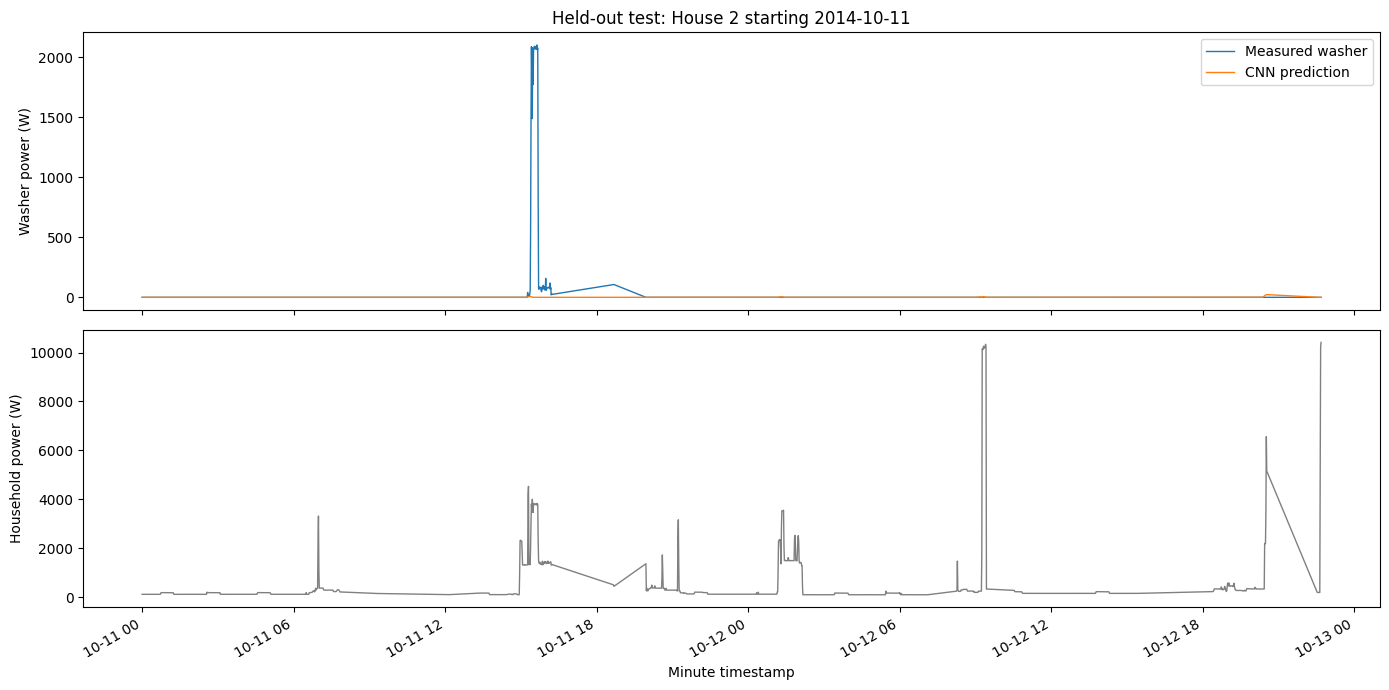

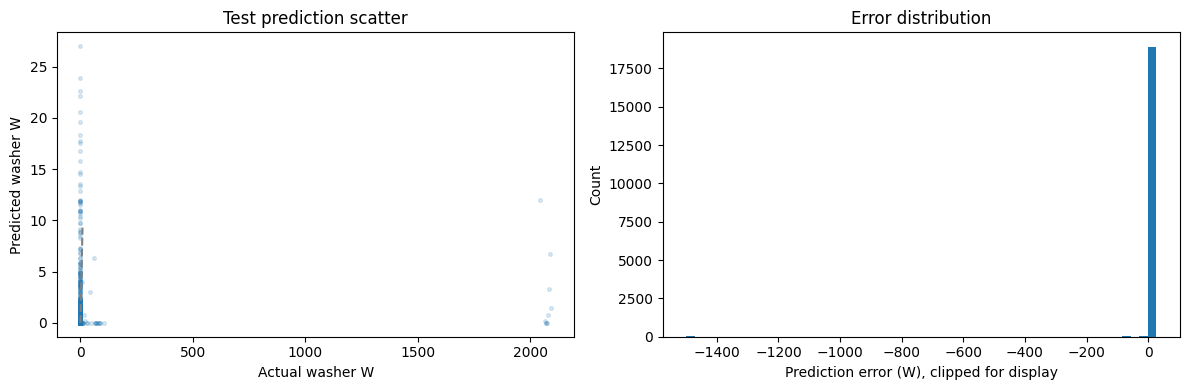

In [17]:
plot_home=int(pred_df.house.iloc[0])
part=pred_df[pred_df.house==plot_home].sort_index()
energy_by_day=part.actual_w.resample('1D').sum(min_count=1).dropna()
plot_day=energy_by_day.idxmax() if len(energy_by_day) else part.index.min().normalize()
view=part.loc[plot_day:plot_day+pd.Timedelta(days=2)-pd.Timedelta(minutes=1)]
fig,axes=plt.subplots(2,1,figsize=(14,7),sharex=True)
view[['actual_w','predicted_w']].rename(columns={'actual_w':'Measured washer','predicted_w':'CNN prediction'}).plot(ax=axes[0],lw=1)
view['aggregate_w'].plot(ax=axes[1],lw=1,color='gray',label='Observed aggregate')
axes[0].set(ylabel='Washer power (W)',title=f'Held-out test: House {plot_home} starting {plot_day:%Y-%m-%d}')
axes[1].set(ylabel='Household power (W)',xlabel='Minute timestamp')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'03_actual_vs_predicted.png',dpi=160);plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(part.actual_w.iloc[::max(1,len(part)//5000)],part.predicted_w.iloc[::max(1,len(part)//5000)],alpha=.16,s=7)
lim=max(float(part.actual_w.quantile(.995)),float(part.predicted_w.quantile(.995)),1)
axes[0].plot([0,lim],[0,lim],linestyle='--',color='gray')
axes[0].set(xlabel='Actual washer W',ylabel='Predicted washer W',title='Test prediction scatter')
error=part.predicted_w-part.actual_w
axes[1].hist(error.clip(-1500,1500),bins=55)
axes[1].set(xlabel='Prediction error (W), clipped for display',ylabel='Count',title='Error distribution')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'03_errors.png',dpi=160);plt.show()

### 4.4 Native vs 15/30-minute comparison and deployment implications


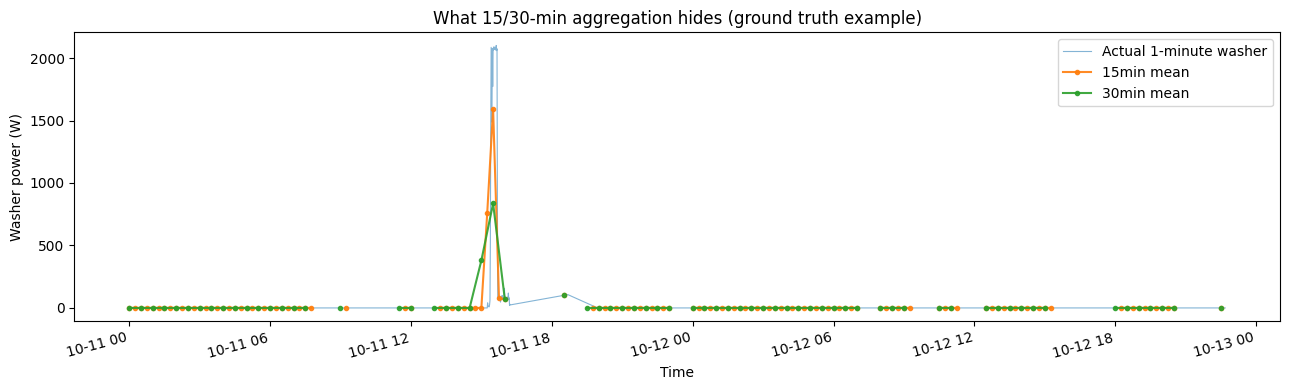

In [18]:
if len(view):
    fig,ax=plt.subplots(figsize=(13,4))
    view.actual_w.plot(ax=ax,label='Actual 1-minute washer',alpha=.55,lw=.8)
    for f in ('15min','30min'):
        view.actual_w.resample(f).mean().plot(ax=ax,label=f'{f} mean',marker='.',alpha=.9)
    ax.set(title='What 15/30-min aggregation hides (ground truth example)',ylabel='Washer power (W)')
    ax.legend();plt.xticks(rotation=15)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/'03_resolution_comparison.png',dpi=160)
    plt.show()

### 4.5 Save model and experiment configuration

In [19]:
import json
model.save(OUTPUT_DIR/'03_seq2point_washer.keras')
run={
 'homes':list(splits),'start_inclusive':START_DATE,'end_exclusive':END_DATE,
 'window_minutes':WINDOW,'active_threshold_W':ACTIVE_W,
 'training_ratio':TRAIN_FRACTION,'validation_ratio':VAL_FRACTION,
 'model':'CNN sequence-to-point','input':'only aggregate 1-min W',
 'target':'official cleaned WM channel 1-min mean W',
 'scaling_train_mean_W':mu,'scaling_train_std_W':sigma,'seed':SEED,
 'issue_exclusion':EXCLUDE_ISSUE_WINDOWS,'active_sample_weight':ACTIVE_SAMPLE_WEIGHT,'epochs_requested':EPOCHS,
 'max_train_windows_per_house':MAX_TRAIN_WINDOWS_PER_HOME,
 'test_samples':int(len(pred_df)),
 'data_limitations':'processed REFIT short-gap filling and zero placeholders'}
(OUTPUT_DIR/'03_experiment.json').write_text(json.dumps(run,indent=2))
print('Outputs:',*[str(p) for p in sorted(OUTPUT_DIR.glob('03_*'))],sep='\n - ')

Outputs:
 - /content/drive/MyDrive/refit/model_results/03_actual_vs_predicted.png
 - /content/drive/MyDrive/refit/model_results/03_data_coverage.csv
 - /content/drive/MyDrive/refit/model_results/03_errors.png
 - /content/drive/MyDrive/refit/model_results/03_experiment.json
 - /content/drive/MyDrive/refit/model_results/03_learning_curve.png
 - /content/drive/MyDrive/refit/model_results/03_resolution_comparison.png
 - /content/drive/MyDrive/refit/model_results/03_seq2point_washer.keras
 - /content/drive/MyDrive/refit/model_results/03_test_metrics.csv
 - /content/drive/MyDrive/refit/model_results/03_test_predictions.csv


## 5. Seq2Seq

In [20]:

SEQ2SEQ_MAX_TRAIN_WINDOWS_PER_HOME=MAX_TRAIN_WINDOWS_PER_HOME
SEQ2SEQ_EPOCHS=EPOCHS
SEQ2SEQ_PATIENCE=5
SEQ2SEQ_BATCH_SIZE=BATCH_SIZE
SEQ2SEQ_LEARNING_RATE=LEARNING_RATE
SEQ2SEQ_ACTIVE_SAMPLE_WEIGHT=1.0
SEQ2SEQ_SEED=SEED+100

print('Seq2Seq configuration:', dict(window=WINDOW, epochs=SEQ2SEQ_EPOCHS,
                                    max_train_windows_per_home=SEQ2SEQ_MAX_TRAIN_WINDOWS_PER_HOME,
                                    issue_exclusion=EXCLUDE_ISSUE_WINDOWS))

Seq2Seq configuration: {'window': 61, 'epochs': 30, 'max_train_windows_per_home': 120000, 'issue_exclusion': True}


### 5.1 Extract *aligned* aggregate and washing-machine target sequences

In [21]:
def select_seq2seq_windows(frame, window=WINDOW):
    """Return raw aggregate inputs, full washer sequences, and original window starts.

    Start indices refer to the original frame, *not* positions in the filtered window list.
    This is essential for correct overlap reconstruction across missing intervals.
    """
    empty=(np.empty((0,window),dtype=np.float32),
           np.empty((0,window),dtype=np.float32),
           np.empty(0,dtype=np.int64))
    if len(frame)<window:
        return empty
    a=frame.aggregate_w.to_numpy(dtype=np.float32)
    y=frame.washer_w.to_numpy(dtype=np.float32)
    valid=np.isfinite(a)&np.isfinite(y)
    if EXCLUDE_ISSUE_WINDOWS:
        valid &= ~frame.issues_flag.to_numpy(dtype=bool)
    starts=np.flatnonzero(sliding_window_view(valid,window).all(axis=1)).astype(np.int64)
    if not len(starts):
        return empty
    X=sliding_window_view(a,window)[starts].copy()
    Y=sliding_window_view(y,window)[starts].copy()
    return X,Y,starts


def subset_seq2seq_training(X,Y,starts,limit,seed):
    """Cap training windows; preserve ON windows based on their midpoint labels."""
    if limit is None or len(X)<=limit:
        return X,Y,starts
    r=np.random.default_rng(seed)
    on=np.flatnonzero(Y[:,WINDOW//2]>=ACTIVE_W)
    off=np.flatnonzero(Y[:,WINDOW//2]<ACTIVE_W)
    n_on=min(len(on),limit//2)
    n_off=min(len(off),limit-n_on)
    remainder=limit-n_on-n_off
    if remainder:
        n_on+=min(remainder,len(on)-n_on)
    chosen=np.sort(np.r_[r.choice(on,n_on,replace=False),r.choice(off,n_off,replace=False)])
    return X[chosen],Y[chosen],starts[chosen]

s2s_coverage=[]
for h,parts in splits.items():
    for split_name,frame in parts.items():
        Xraw,Yraw,starts=select_seq2seq_windows(frame)
        s2s_coverage.append({
            'house':h,'split':split_name,'total_minutes':len(frame),
            'valid_paired_minutes':int((np.isfinite(frame.aggregate_w)&np.isfinite(frame.washer_w)).sum()),
            'eligible_full_seq2seq_windows':len(starts),
            'active_midpoint_windows':int((Yraw[:,WINDOW//2]>=ACTIVE_W).sum()) if len(starts) else 0,
            'coverage_start':str(frame.index.min()),'coverage_end':str(frame.index.max()),
        })
s2s_coverage_df=pd.DataFrame(s2s_coverage)
display(s2s_coverage_df)
s2s_coverage_df.to_csv(OUTPUT_DIR/'03_seq2seq_coverage.csv',index=False)

,house,split,total_minutes,valid_paired_minutes,eligible_full_seq2seq_windows,active_midpoint_windows,coverage_start,coverage_end
0,1,train,154224,149081,99497,22,2014-06-01 00:00:00,2014-09-16 02:23:00
1,1,val,33048,32936,21619,91,2014-09-16 02:24:00,2014-10-09 01:11:00
2,1,test,33048,30746,19977,12,2014-10-09 01:12:00,2014-10-31 23:59:00
3,2,train,154224,153507,89416,64,2014-06-01 00:00:00,2014-09-16 02:23:00
4,2,val,33048,32883,17292,0,2014-09-16 02:24:00,2014-10-09 01:11:00
5,2,test,33048,31776,19006,73,2014-10-09 01:12:00,2014-10-31 23:59:00
6,3,train,154224,149294,71683,148,2014-06-01 00:00:00,2014-09-16 02:23:00
7,3,val,33048,32867,17042,93,2014-09-16 02:24:00,2014-10-09 01:11:00
8,3,test,33048,31479,16840,29,2014-10-09 01:12:00,2014-10-31 23:59:00


### 5.2 Build training and validation sequences

In [22]:
s2s_X_train_parts=[];s2s_y_train_parts=[]
s2s_X_val_parts=[];s2s_y_val_parts=[]
for h,parts in splits.items():
    Xw,Yw,st=select_seq2seq_windows(parts['train'])
    Xw,Yw,st=subset_seq2seq_training(Xw,Yw,st,SEQ2SEQ_MAX_TRAIN_WINDOWS_PER_HOME,SEQ2SEQ_SEED+h)
    Xv,Yv,_=select_seq2seq_windows(parts['val'])
    print(f'House {h}: Seq2Seq train {len(Xw):,} windows; val {len(Xv):,} windows; '
          f'train ON midpoint {(Yw[:,WINDOW//2]>=ACTIVE_W).sum() if len(Yw) else 0:,}')
    if len(Xw):
        s2s_X_train_parts.append(((Xw-mu)/sigma)[...,None].astype('float32'))
        s2s_y_train_parts.append((Yw/1000).astype('float32'))
    if len(Xv):
        s2s_X_val_parts.append(((Xv-mu)/sigma)[...,None].astype('float32'))
        s2s_y_val_parts.append((Yv/1000).astype('float32'))
    del Xw,Yw,Xv,Yv,st

if not s2s_X_train_parts or not s2s_X_val_parts:
    raise RuntimeError('No full-label Seq2Seq windows; inspect label gaps, date coverage, and Issues policy.')
X_train_seq2seq=np.concatenate(s2s_X_train_parts)
y_train_seq2seq=np.concatenate(s2s_y_train_parts)
X_val_seq2seq=np.concatenate(s2s_X_val_parts)
y_val_seq2seq=np.concatenate(s2s_y_val_parts)
del s2s_X_train_parts,s2s_y_train_parts,s2s_X_val_parts,s2s_y_val_parts
print('Seq2Seq train shapes:',X_train_seq2seq.shape,y_train_seq2seq.shape)
print('Seq2Seq validation shapes:',X_val_seq2seq.shape,y_val_seq2seq.shape)
assert X_train_seq2seq.shape[1:]==(WINDOW,1)
assert y_train_seq2seq.shape[1:]==(WINDOW,)
assert np.isfinite(X_train_seq2seq).all() and np.isfinite(y_train_seq2seq).all()
assert np.isfinite(X_val_seq2seq).all() and np.isfinite(y_val_seq2seq).all()

House 1: Seq2Seq train 99,497 windows; val 21,619 windows; train ON midpoint 22
House 2: Seq2Seq train 89,416 windows; val 17,292 windows; train ON midpoint 64
House 3: Seq2Seq train 71,683 windows; val 17,042 windows; train ON midpoint 148
Seq2Seq train shapes: (260596, 61, 1) (260596, 61)
Seq2Seq validation shapes: (55953, 61, 1) (55953, 61)


### 5.3 Build and train the paper-style CNN Seq2Seq

In [23]:
def make_seq2seq(window_length):
    if window_length < 30:
        raise ValueError('Five valid convolutions need window_length >= 30')
    inp=keras.Input(shape=(window_length,1),name='seq2seq_aggregate_window_1min')
    x=layers.Conv1D(30,10,strides=1,padding='valid',activation='relu',name='s2s_conv_1')(inp)
    x=layers.Conv1D(30, 8,strides=1,padding='valid',activation='relu',name='s2s_conv_2')(x)
    x=layers.Conv1D(40, 6,strides=1,padding='valid',activation='relu',name='s2s_conv_3')(x)
    x=layers.Conv1D(50, 5,strides=1,padding='valid',activation='relu',name='s2s_conv_4')(x)
    x=layers.Conv1D(50, 5,strides=1,padding='valid',activation='relu',name='s2s_conv_5')(x)
    x=layers.Flatten(name='s2s_flatten')(x)
    x=layers.Dense(1024,activation='relu',name='s2s_dense_1024')(x)
    out=layers.Dense(window_length,activation='linear',name='washer_full_window')(x)
    return keras.Model(inp,out,name='Seq2SeqCNN_PaperStyle')

seq2seq_model=make_seq2seq(WINDOW)
seq2seq_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=SEQ2SEQ_LEARNING_RATE),
    loss='mse',
    metrics=[keras.metrics.MeanAbsoluteError(name='window_mae_kW')]
)
seq2seq_model.summary()
assert seq2seq_model.output_shape==(None,WINDOW)
assert [l.filters for l in seq2seq_model.layers if isinstance(l,layers.Conv1D)]==[30,30,40,50,50]
assert [l.kernel_size[0] for l in seq2seq_model.layers if isinstance(l,layers.Conv1D)]==[10,8,6,5,5]

Model: "Seq2SeqCNN_PaperStyle"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ seq2seq_aggregate_window_1min   │ (None, 61, 1)          │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s2s_conv_1 (Conv1D)             │ (None, 52, 30)         │           330 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s2s_conv_2 (Conv1D)             │ (None, 45, 30)         │         7,230 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s2s_conv_3 (Conv1D)             │ (None, 40, 40)         │         7,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s2s_conv_4 (Conv1D)             │ (None, 36, 50)         │        10,050 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s2s_conv_5 (Conv1D)             │ (None, 32, 50)         │        12,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s2s_flatten (Flatten)           │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s2s_dense_1024 (Dense)          │ (None, 1024)           │     1,639,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ washer_full_window (Dense)      │ (None, 61)             │        62,525 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,739,349 (6.64 MB)

 Trainable params: 1,739,349 (6.64 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
1018/1018 - 15s - 15ms/step - loss: 3.6895e-04 - val_loss: 0.0011 - val_window_mae_kW: 0.0015 - window_mae_kW: 8.8478e-04
Epoch 2/30
1018/1018 - 7s - 7ms/step - loss: 3.6667e-04 - val_loss: 0.0011 - val_window_mae_kW: 0.0014 - window_mae_kW: 8.1673e-04
Epoch 3/30
1018/1018 - 6s - 6ms/step - loss: 3.6672e-04 - val_loss: 0.0011 - val_window_mae_kW: 0.0014 - window_mae_kW: 7.6179e-04
Epoch 4/30
1018/1018 - 7s - 7ms/step - loss: 3.6672e-04 - val_loss: 0.0011 - val_window_mae_kW: 0.0014 - window_mae_kW: 7.5946e-04
Epoch 5/30
1018/1018 - 7s - 7ms/step - loss: 3.6672e-04 - val_loss: 0.0011 - val_window_mae_kW: 0.0014 - window_mae_kW: 7.5956e-04
Epoch 6/30
1018/1018 - 9s - 9ms/step - loss: 3.6672e-04 - val_loss: 0.0011 - val_window_mae_kW: 0.0014 - window_mae_kW: 7.6058e-04


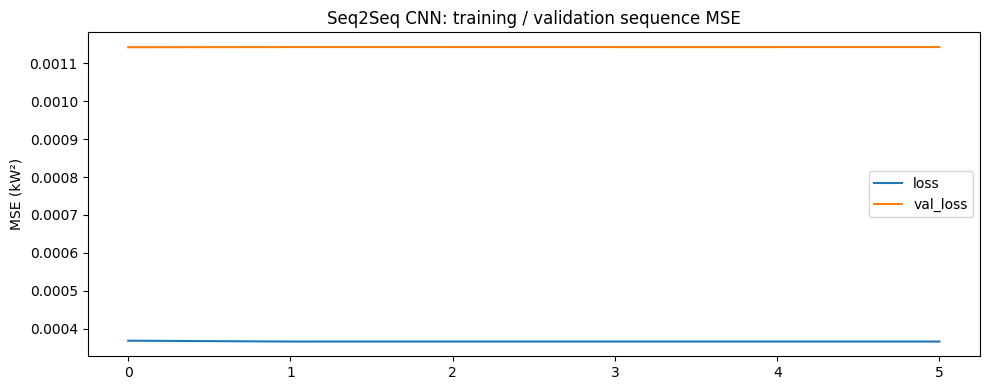

In [24]:
seq2seq_sample_weight=np.where(
    y_train_seq2seq[:,WINDOW//2]>=ACTIVE_W/1000,
    SEQ2SEQ_ACTIVE_SAMPLE_WEIGHT,1.0
).astype('float32')

seq2seq_history=seq2seq_model.fit(
    X_train_seq2seq,y_train_seq2seq,
    sample_weight=seq2seq_sample_weight,
    validation_data=(X_val_seq2seq,y_val_seq2seq),
    epochs=SEQ2SEQ_EPOCHS,batch_size=SEQ2SEQ_BATCH_SIZE,verbose=2,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor='val_loss',patience=SEQ2SEQ_PATIENCE,restore_best_weights=True
    )]
)
pd.DataFrame(seq2seq_history.history)[['loss','val_loss']].plot(
    figsize=(10,4),title='Seq2Seq CNN: training / validation sequence MSE'
)
plt.ylabel('MSE (kW²)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'03_seq2seq_learning_curve.png',dpi=150)
plt.show()

### 5.4 Reconstruct the full predicted signal by averaging overlaps

In [25]:
def overlap_average(pred_windows, starts, n_minutes):
    """Average overlapping windows into original timeline; uncovered locations stay NaN."""
    pred_windows=np.asarray(pred_windows)
    starts=np.asarray(starts,dtype=np.int64)
    if pred_windows.ndim!=2 or len(pred_windows)!=len(starts):
        raise ValueError('Prediction shape and window starts must agree.')
    width=pred_windows.shape[1]
    if len(starts) and (starts.min()<0 or starts.max()+width>n_minutes):
        raise ValueError('Window starts out of timeline bounds.')
    total=np.zeros(n_minutes,dtype=np.float64)
    count=np.zeros(n_minutes,dtype=np.int32)
    for j in range(width):
        np.add.at(total,starts+j,pred_windows[:,j])
        np.add.at(count,starts+j,1)
    result=np.full(n_minutes,np.nan,dtype=np.float64)
    np.divide(total,count,out=result,where=count>0)
    return result,count

# Reconstruction self-test: minute 1 is average of 20 W (window 1) and 40 W (window 2).
toy,c=overlap_average(np.array([[10.,20.,30.],[40.,50.,60.]]),[0,1],4)
assert np.allclose(toy,[10,30,40,60]) and c.tolist()==[1,2,2,1]

seq2seq_predictions=[];seq2seq_raw_scores=[];reconstruction_audit=[]
for h,parts in splits.items():
    test_frame=parts['test']
    Xt,Yt,starts=select_seq2seq_windows(test_frame)
    if not len(starts):
        print(f'House {h}: no complete Seq2Seq test windows; skipped')
        continue
    Xt_norm=((Xt-mu)/sigma)[...,None].astype('float32')
    pred_windows_kW=seq2seq_model.predict(Xt_norm,batch_size=2048,verbose=0)
    pred_raw_w,count=overlap_average(pred_windows_kW*1000.0,starts,len(test_frame))
    aggregate=test_frame.aggregate_w.to_numpy(dtype=np.float32)
    actual=test_frame.washer_w.to_numpy(dtype=np.float32)
    predicted=np.clip(pred_raw_w,0,np.maximum(aggregate,0))
    valid=(count>0)&np.isfinite(actual)&np.isfinite(aggregate)&np.isfinite(predicted)
    df=pd.DataFrame({
        'house':h,'actual_w':actual[valid],'seq2seq_w':predicted[valid],
        'aggregate_w':aggregate[valid],'overlap_count':count[valid],
    },index=test_frame.index[valid])
    df.index.name='Time'
    seq2seq_predictions.append(df)
    seq2seq_raw_scores.append({'house':h,'method':'Seq2Seq CNN',
        'n_test_minutes':len(df),**score(df.actual_w,df.seq2seq_w)})
    reconstruction_audit.append({'house':h,'test_minutes':len(test_frame),
        'valid_input_target_windows':len(starts),
        'reconstructed_test_minutes':int(valid.sum()),
        'overlap_count_median':float(np.median(count[valid])) if valid.any() else None})

if not seq2seq_predictions:
    raise RuntimeError('Seq2Seq test prediction is empty. Check per-house coverage and timestamps.')
seq2seq_pred_df=pd.concat(seq2seq_predictions).sort_index(kind='stable')
display(pd.DataFrame(reconstruction_audit))
display(pd.DataFrame(seq2seq_raw_scores).round(3))
seq2seq_pred_df.to_csv(OUTPUT_DIR/'03_seq2seq_test_predictions.csv')

,house,test_minutes,valid_input_target_windows,reconstructed_test_minutes,overlap_count_median
0,1,33048,19977,28077,56.0
1,2,33048,19006,26806,57.0
2,3,33048,16840,25600,47.0


,house,method,n_test_minutes,MAE_W,RMSE_W,precision_on,recall_on,F1_on,true_kWh,pred_kWh,SAE
0,1,Seq2Seq CNN,28077,3.043,61.352,0.0,0.0,0.0,1.293,0.136,0.895
1,2,Seq2Seq CNN,26806,8.149,117.335,0.0,0.0,0.0,3.517,0.134,0.962
2,3,Seq2Seq CNN,25600,2.559,47.102,0.0,0.0,0.0,0.964,0.136,0.859


In [26]:
comparable=[];common_scores=[]
for h in splits:
    s2p=pred_df.loc[pred_df.house==h,['actual_w','predicted_w','aggregate_w']].sort_index()
    s2s=seq2seq_pred_df.loc[seq2seq_pred_df.house==h,['actual_w','seq2seq_w','overlap_count']].sort_index()
    if s2p.empty or s2s.empty:
        continue
    match=s2p.join(s2s,how='inner',lsuffix='_point',rsuffix='_seq')
    if match.empty:
        continue
    if not np.allclose(match.actual_w_point.to_numpy(),match.actual_w_seq.to_numpy(),atol=1e-3):
        raise AssertionError(f'House {h}: Seq2Point vs Seq2Seq ground-truth timestamps misaligned!')
    match=match.rename(columns={'actual_w_point':'actual_w',
          'predicted_w':'seq2point_w','aggregate_w':'aggregate_w',
          'seq2seq_w':'seq2seq_w'})
    match['house']=h
    match=match.drop(columns=['actual_w_seq'])
    comparable.append(match)
    yy=match.actual_w.to_numpy()
    for method,estimate in [
        ('Seq2Point CNN',match.seq2point_w.to_numpy()),
        ('Seq2Seq CNN',match.seq2seq_w.to_numpy()),
        ('Always off',np.zeros_like(yy)),
    ]:
        common_scores.append({'house':h,'method':method,'n_test_minutes':len(yy),
                              **score(yy,estimate)})

if not comparable:
    raise RuntimeError('No shared test timestamps between Seq2Point and Seq2Seq.')
common_pred_df=pd.concat(comparable).sort_index(kind='stable')
for method,col in [('Seq2Point CNN','seq2point_w'),('Seq2Seq CNN','seq2seq_w')]:
    assert np.isfinite(common_pred_df[col]).all()

pooled_y=common_pred_df.actual_w.to_numpy()
for method,col in [('Seq2Point CNN','seq2point_w'),('Seq2Seq CNN','seq2seq_w')]:
    common_scores.append({'house':'POOLED','method':method,
        'n_test_minutes':len(pooled_y),**score(pooled_y,common_pred_df[col].to_numpy())})
common_scores.append({'house':'POOLED','method':'Always off',
    'n_test_minutes':len(pooled_y),**score(pooled_y,np.zeros_like(pooled_y))})

common_metrics_df=pd.DataFrame(common_scores)
print('Identical-minute comparison (including pooled tests):')
display(common_metrics_df.round(3))
print('WARNING: Train/test are separated chronologically WITHIN each home; this is not unseen-household generalization.')
common_pred_df.to_csv(OUTPUT_DIR/'03_seq2seq_vs_seq2point_common_predictions.csv')
common_metrics_df.to_csv(OUTPUT_DIR/'03_seq2seq_vs_seq2point_common_metrics.csv',index=False)

Identical-minute comparison (including pooled tests):


,house,method,n_test_minutes,MAE_W,RMSE_W,precision_on,recall_on,F1_on,true_kWh,pred_kWh,SAE
0,1,Seq2Point CNN,19977,0.362,5.766,0.000,0.000,0.000,0.036,0.086,1.373
1,1,Seq2Seq CNN,19977,0.360,5.665,0.000,0.000,0.000,0.036,0.084,1.310
2,1,Always off,19977,0.109,5.666,0.000,0.000,0.000,0.036,0.000,1.000
3,2,Seq2Point CNN,19006,3.149,74.923,0.000,0.000,0.000,0.950,0.052,0.946
4,2,Seq2Seq CNN,19006,3.235,74.972,0.000,0.000,0.000,0.950,0.077,0.919
5,2,Always off,19006,2.998,75.002,0.000,0.000,0.000,0.950,0.000,1.000
6,3,Seq2Point CNN,16840,0.557,8.046,0.079,0.172,0.109,0.084,0.081,0.034
7,3,Seq2Seq CNN,16840,0.545,8.103,0.000,0.000,0.000,0.084,0.072,0.141
8,3,Always off,16840,0.300,8.104,0.000,0.000,0.000,0.084,0.000,1.000
9,POOLED,Seq2Point CNN,55823,1.370,44.075,0.049,0.044,0.046,1.070,0.219,0.795


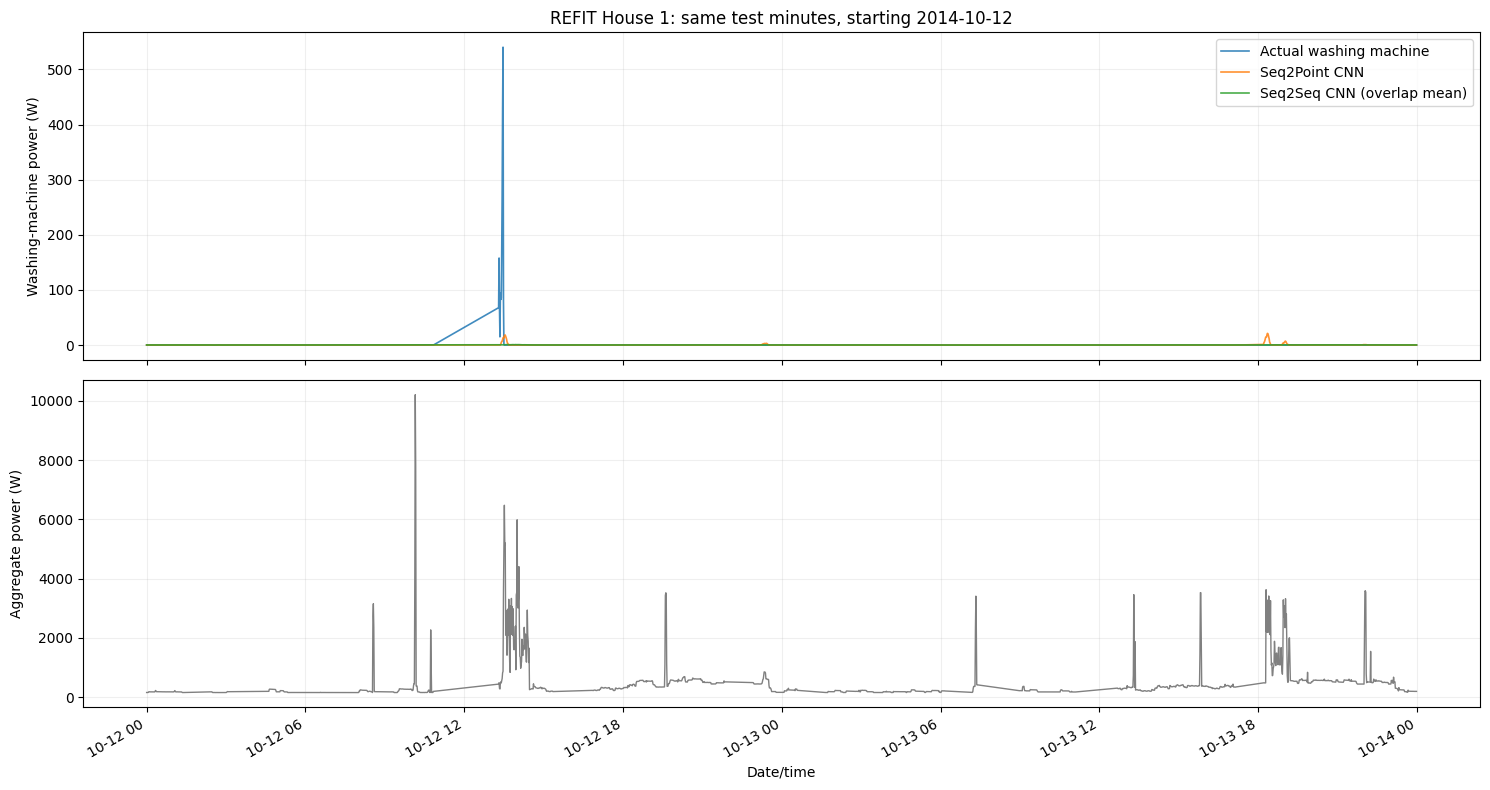

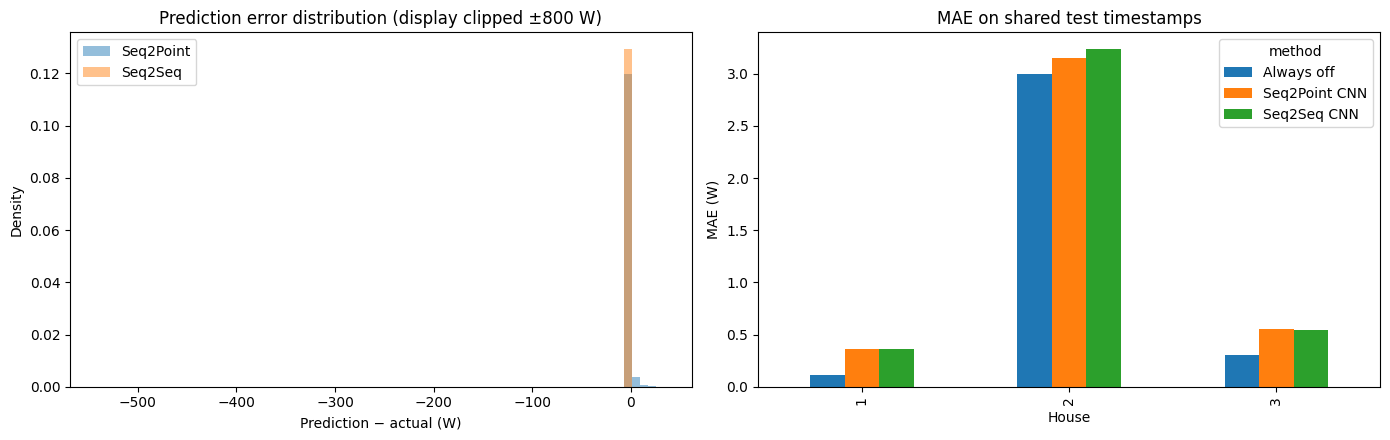

In [27]:
plot_house=int(common_pred_df.house.value_counts().idxmax())
comparison=common_pred_df.loc[common_pred_df.house==plot_house].sort_index()
wm_energy_daily=comparison.actual_w.resample('D').sum(min_count=1).dropna()
plot_day=wm_energy_daily.idxmax()
view_compare=comparison.loc[plot_day:plot_day+pd.Timedelta(days=2)-pd.Timedelta(minutes=1)]
fig,axes=plt.subplots(2,1,figsize=(15,8),sharex=True)
view_compare[['actual_w','seq2point_w','seq2seq_w']].rename(columns={
    'actual_w':'Actual washing machine','seq2point_w':'Seq2Point CNN',
    'seq2seq_w':'Seq2Seq CNN (overlap mean)'
}).plot(ax=axes[0],lw=1.2,alpha=0.85)
view_compare.aggregate_w.plot(ax=axes[1],color='gray',lw=1,label='Aggregate house power')
axes[0].set(ylabel='Washing-machine power (W)',
    title=f'REFIT House {plot_house}: same test minutes, starting {plot_day:%Y-%m-%d}')
axes[1].set(ylabel='Aggregate power (W)',xlabel='Date/time')
axes[0].grid(alpha=0.2);axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'03_seq2seq_vs_seq2point_trace.png',dpi=160)
plt.show()

fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for col,label in [('seq2point_w','Seq2Point'),('seq2seq_w','Seq2Seq')]:
    err=comparison[col]-comparison.actual_w
    axes[0].hist(np.clip(err,-800,800),bins=70,alpha=.48,label=label,density=True)
axes[0].set(title='Prediction error distribution (display clipped ±800 W)',
    xlabel='Prediction − actual (W)',ylabel='Density')
axes[0].legend()
perhome=common_metrics_df.loc[common_metrics_df.house!='POOLED'].copy()
perhome['house']=perhome['house'].astype(str)
perhome.pivot(index='house',columns='method',values='MAE_W').plot(kind='bar',ax=axes[1])
axes[1].set(title='MAE on shared test timestamps',xlabel='House',ylabel='MAE (W)')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'03_seq2seq_vs_seq2point_diagnostics.png',dpi=160)
plt.show()

### 5.5 Save the Seq2Seq model, metrics and configuration

In [28]:
seq2seq_model.save(OUTPUT_DIR/'03_seq2seq_washer.keras')
seq2seq_run={
    'paper':'Zhang et al. (2018) Sequence-to-point learning with neural networks for NILM, Figure 1',
    'architecture':'Paper-style five-layer CNN Seq2Seq, 30/30/40/50/50 kernels 10/8/6/5/5, Dense(1024), Dense(WINDOW)',
    'REFIT_adaptations':['1-minute inputs, 61-minute windows',
                         'chronological train/val/test per home',
                         'training-only aggregate normalization',
                         'ignore missing or flagged windows',
                         'overlap averaging for per-minute inference'],
    'homes':list(map(int,splits)),'start_inclusive':START_DATE,'end_exclusive':END_DATE,
    'window_minutes':int(WINDOW),'active_threshold_watts':float(ACTIVE_W),
    'input_normalization_mean_W':float(mu),'input_normalization_std_W':float(sigma),
    'target_unit_during_training':'kW (watts/1000)',
    'issue_exclusion':bool(EXCLUDE_ISSUE_WINDOWS),
    'Seq2Point_active_weight':float(ACTIVE_SAMPLE_WEIGHT),
    'Seq2Seq_active_weight':float(SEQ2SEQ_ACTIVE_SAMPLE_WEIGHT),
    'Seq2Seq_epochs_requested':int(SEQ2SEQ_EPOCHS),
    'Seq2Seq_max_windows_per_home':int(SEQ2SEQ_MAX_TRAIN_WINDOWS_PER_HOME),
    'evaluation':'same intersected per-house test-minute timestamps, pooled and per-house metrics',
    'same_timestep_evaluated_minutes':int(len(common_pred_df)),
    'limitations':['within-household split, not unseen-household test',
                   'full-sequence target windows reduce usable data versus midpoint-only labels',
                   'competing load signatures and REFIT label quality']
}
(OUTPUT_DIR/'03_seq2seq_experiment.json').write_text(json.dumps(seq2seq_run,indent=2))
print('Seq2Seq outputs saved to:',OUTPUT_DIR)
for p in sorted(OUTPUT_DIR.glob('03_seq2seq*')):
    print(' •',p.name)

Seq2Seq outputs saved to: /content/drive/MyDrive/refit/model_results
 • 03_seq2seq_coverage.csv
 • 03_seq2seq_experiment.json
 • 03_seq2seq_learning_curve.png
 • 03_seq2seq_test_predictions.csv
 • 03_seq2seq_vs_seq2point_common_metrics.csv
 • 03_seq2seq_vs_seq2point_common_predictions.csv
 • 03_seq2seq_vs_seq2point_diagnostics.png
 • 03_seq2seq_vs_seq2point_trace.png
 • 03_seq2seq_washer.keras
